In [4]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re
from nltk.tokenize import word_tokenize
import spacy
from nltk.corpus import stopwords
!pip install pandas numpy scikit-learn nltk spacy
!python -m spacy download en_core_web_sm




     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 36.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [14]:
# Step 1: Install the Kaggle package
!pip install -q kaggle

# Step 2: Set up the Kaggle API key
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Step 3: Download a test IMDb dataset
!kaggle datasets download -d aakashsaroop/movie-genreplotposter

# Step 4: Check the current directory for downloaded files
!ls -l

# Unzip the downloaded dataset
!unzip '*.zip' -d dataset

# Step 5: Load the dataset
import pandas as pd

# List the contents of the unzipped dataset directory
!ls dataset/

# Load the CSV file, specifying the correct path within the 'dataset' folder
df = pd.read_csv('dataset/Movie_combined.csv')

# Display the first few rows
df.head()

Dataset URL: https://www.kaggle.com/datasets/aakashsaroop/movie-genreplotposter
License(s): CC0-1.0
 61% 9.00M/14.7M [00:00<00:00, 13.7MB/s]
100% 14.7M/14.7M [00:00<00:00, 23.8MB/s]
total 15192
drwxr-xr-x 2 root root     4096 Oct 31 16:05 dataset
-rw-r--r-- 1 root root    77303 Mar 27  2024 imdb-dataset-top-2000-movies.zip
-rw-r--r-- 1 root root       68 Oct 31 15:35 kaggle.json
-rw-r--r-- 1 root root 15464251 Dec 27  2021 movie-genreplotposter.zip
drwxr-xr-x 1 root root     4096 Oct 29 13:25 sample_data
Archive:  imdb-dataset-top-2000-movies.zip
replace dataset/imdb_top_2000_movies.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: Y
  inflating: dataset/imdb_top_2000_movies.csv  

Archive:  movie-genreplotposter.zip
  inflating: dataset/Movie_combined.csv  

2 archives were successfully processed.
imdb_top_2000_movies.csv  Movie_combined.csv


,Unnamed: 0,Title,Genre,Plot,Poster
0,0,the great train robbery,action,The film opens with two bandits breaking into ...,https://m.media-amazon.com/images/M/MV5BOWE4M2...
1,1,the suburbanite,comedy,The film is about a family who move to the sub...,https://m.media-amazon.com/images/M/MV5BMTUwOT...
2,2,how brown saw the baseball game,comedy,Before heading out to a baseball game at a nea...,0
3,5,the adventures of dollie,drama,On a beautiful summer day a father and mother ...,https://m.media-amazon.com/images/M/MV5BMDlmYz...
4,6,the black viper,drama,A thug accosts a girl as she leaves her workpl...,https://m.media-amazon.com/images/M/MV5BZDVjYT...


In [16]:
# Drop the 'Unnamed: 0' column and any rows with missing values
df.drop(columns=['Unnamed: 0'], inplace=True)
df.dropna(subset=['Plot', 'Genre'], inplace=True)

# Check the cleaned dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17303 entries, 0 to 17302
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Title   17303 non-null  object
 1   Genre   17303 non-null  object
 2   Plot    17303 non-null  object
 3   Poster  16697 non-null  object
dtypes: object(4)
memory usage: 540.8+ KB
None


In [20]:
def preprocess_text(text):
    # Remove special characters and convert to lowercase
    text = re.sub(r'\W', ' ', text.lower())
    # Remove stopwords using a set for faster lookup
    stop_words = set(stopwords.words('english'))
    tokens = text.split()  # Use split instead of word_tokenize for speed
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)


In [23]:
# Apply preprocessing to the 'Plot' column
df['cleaned_plot'] = df['Plot'].apply(preprocess_text)

In [24]:
# Check the preprocessed data
print(df[['Title', 'cleaned_plot', 'Genre']].head())

                             Title  \
0          the great train robbery   
1                  the suburbanite   
2  how brown saw the baseball game   
3         the adventures of dollie   
4                  the black viper   

                                        cleaned_plot   Genre  
0  film opens two bandits breaking railroad teleg...  action  
1  film family move suburbs hoping quiet life thi...  comedy  
2  heading baseball game nearby ballpark sports f...  comedy  
3  beautiful summer day father mother take daught...   drama  
4  thug accosts girl leaves workplace man rescues...   drama  


In [25]:
# Split the data into features (X) and target variable (y)
X = df['cleaned_plot']
y = df['Genre']

In [27]:
!pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer


# Create a TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# Vectorize the text data
X_vectorized = vectorizer.fit_transform(X)

# Now you can split the data
X_train, X_test, y_train, y_test = train_test_split(X_vectorized, y, test_size=0.2, random_state=42)

In [29]:

from sklearn.naive_bayes import MultinomialNB

# Train a Naive Bayes classifier
model = MultinomialNB()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[ 195    0    2  548    0    0]
 [   9    0   21   74    0    0]
 [   8    0  116  746    0    0]
 [   8    0    4 1122    0    0]
 [   1    0    1  170    0    0]
 [  10    0    3  421    0    2]]

Classification Report:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

      action       0.84      0.26      0.40       745
   animation       0.00      0.00      0.00       104
      comedy       0.79      0.13      0.23       870
       drama       0.36      0.99      0.53      1134
     romance       0.00      0.00      0.00       172
    thriller       1.00      0.00      0.01       436

    accuracy                           0.41      3461
   macro avg       0.50      0.23      0.19      3461
weighted avg       0.63      0.41      0.32      3461



In [32]:

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print the accuracy
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.41


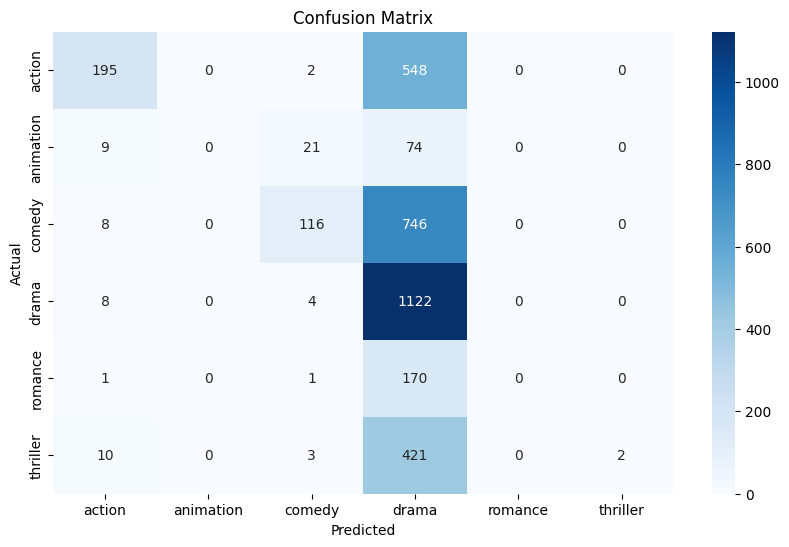

In [31]:
# Plotting the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()